# Figure S4a
Probability of a correct guess of the initial vertex for graphs with $N=10$ at $r=2$, averaged over the instances of each random graph family.

In [1]:
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from fixloc import style as S

d = json.load(open('data.json'))

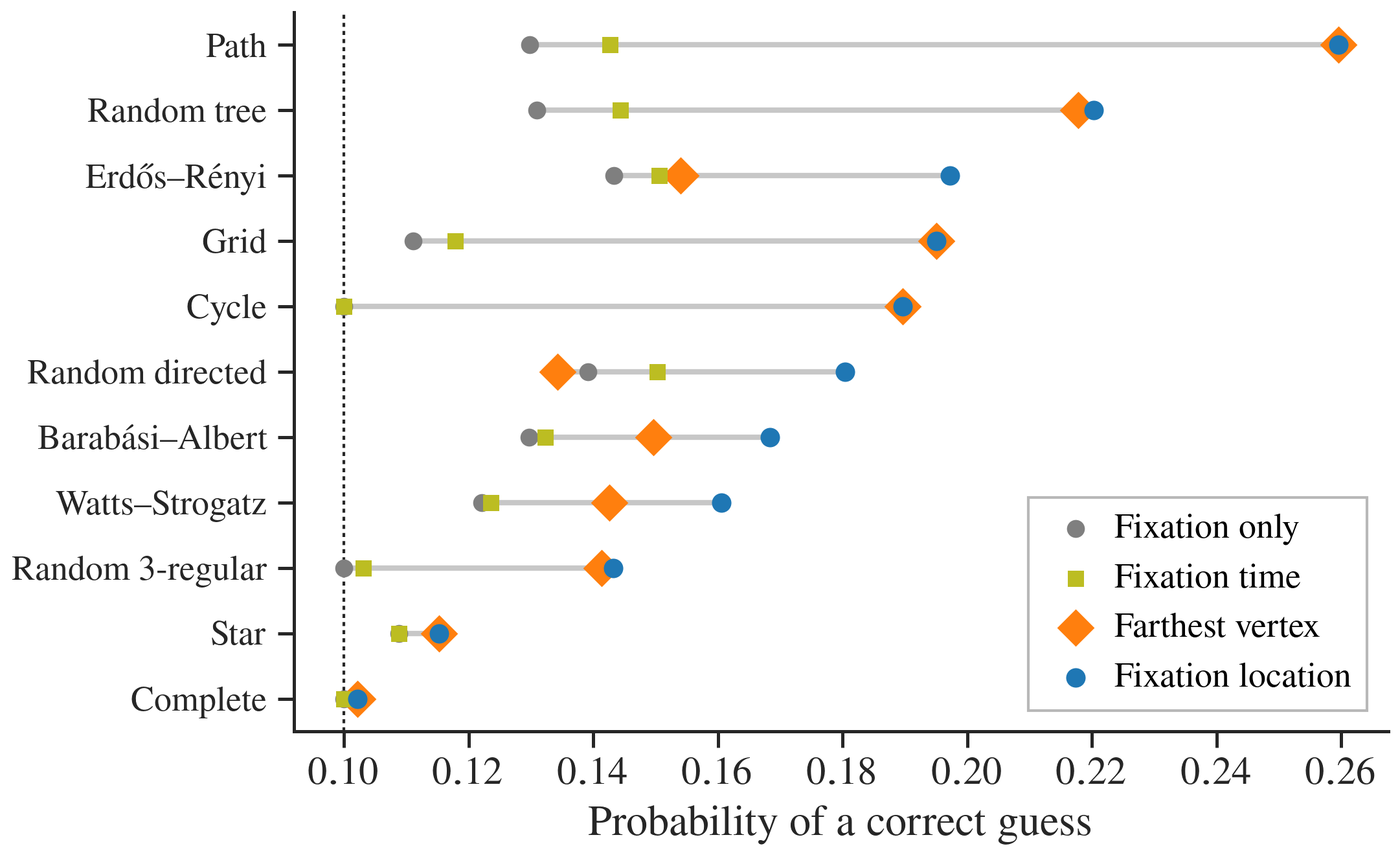

In [2]:
NAMES = {
  'Erdos-Renyi': r"Erd\H{o}s--R\'enyi",
  'Barabasi-Albert': r"Barab\'asi--Albert",
  'random digraph': 'random directed',
  'small-world': 'Watts--Strogatz',
}
COLS = ['prior_best', 'acc_duration', 'acc_farthest', 'acc_location']


def name(family):
  s = NAMES.get(family, family)
  return s[0].upper() + s[1:]


g = pd.DataFrame(d['rows']).groupby('family')[COLS].mean().sort_values('acc_location')
y = np.arange(len(g))
fig = plt.figure(figsize=(4.4, 2.5))
ax = fig.add_axes([0.33, 0.2, 0.64, 0.74])
for i in y:
  vals = g.iloc[i][COLS]
  ax.plot([vals.min(), vals.max()], [i, i], color=S.LGRAY, lw=1.0, zorder=1)
for col, c, lab, mk, sz, zo in (
  ('prior_best', S.GRAY, 'Fixation only', 'o', 11, 3),
  ('acc_duration', S.OLIVE, 'Fixation time', 's', 9, 3),
  ('acc_farthest', S.ORANGE, 'Farthest vertex', 'D', 24, 2.5),
  ('acc_location', S.BLUE, 'Fixation location', 'o', 13, 3),
):
  ax.scatter(g[col], y, color=c, s=sz, marker=mk, label=lab, zorder=zo, lw=0)
ax.axvline(0.1, color=S.INK, lw=0.5, ls=(0, (1.5, 1.5)))
ax.set_yticks(y, [name(f) for f in g.index])
ax.tick_params(axis='y', labelsize=6.5)
ax.set_xlabel('Probability of a correct guess')
S.legend(ax, loc='lower right', handletextpad=0.2, fontsize=6.5)
S.save_panel(fig, 'a')